# Progress 3: Diferensiasi, Pemodelan SARIMA, Diagnostik Residual, dan Evaluasi Validasi

*Daffa Muhammad Khrisadi / 24083010062 / Analisis Deret Waktu A*

Notebook ini melanjutkan Progress 1 (eksplorasi data, uji stasioneritas awal, dan baseline) serta Progress 2 (draf poster 50%). Fokus pada tahap ini adalah diferensiasi, identifikasi dan estimasi kandidat model SARIMA pada data latih, pengecekan diagnostik residual, serta evaluasi akurasi di data validasi. Data uji (2024-Q4 sampai 2026-Q3) tetap dikunci sampai tahap perbandingan akhir bersama model SVR.

---
## 1. Pemuatan Data, Pembagian Kronologis, dan Rekapitulasi Baseline

In [1]:
import pathlib
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.03)

PALETTE = {
    'actual': '#111111',
    'train': '#4a5568',
    'sarima_best': '#1f77b4',
    'sarima_alt1': '#17becf',
    'sarima_alt2': '#2b5c8f',
    'sarima_alt3': '#d62728',
    'naive': '#9467bd',
    'snaive': '#ff7f0e',
    'ols': '#2ca02c',
}

# Muat dataset dan bagi secara kronologis (sama seperti Progress 1)
DATA_PATH = pathlib.Path('../data/pdb_industri_makanan_minuman_bps.csv')
df = pd.read_csv(DATA_PATH)
df['tanggal'] = pd.to_datetime(df['tanggal'])

N_VAL = 8
N_TEST = 8
N_TRAIN = len(df) - N_VAL - N_TEST

train_df = df.iloc[:N_TRAIN].copy()
val_df = df.iloc[N_TRAIN:N_TRAIN + N_VAL].copy()
test_df = df.iloc[N_TRAIN + N_VAL:].copy()  # Dikunci untuk evaluasi akhir

y_train = train_df['pdb_mamin_adhk_miliar_rp'].values
y_val = val_df['pdb_mamin_adhk_miliar_rp'].values
log_y_train = np.log(y_train)

# Penyebut MASE: MAE in-sample Seasonal Naive (s = 4) pada Training Set
MASE_DENOM = float(np.mean(np.abs(y_train[4:] - y_train[:-4])))

print(f"Training Set   : {train_df['periode'].iloc[0]} s.d. {train_df['periode'].iloc[-1]} ({len(train_df)} observasi)")
print(f"Validation Set : {val_df['periode'].iloc[0]} s.d. {val_df['periode'].iloc[-1]} ({len(val_df)} observasi)")
print(f"Test Set       : {test_df['periode'].iloc[0]} s.d. {test_df['periode'].iloc[-1]} ({len(test_df)} observasi - dikunci)")
print(f"Penyebut MASE (in-sample Seasonal Naive s=4 pada Train): {MASE_DENOM:,.2f} Miliar Rp")


def evaluate_forecast(y_true: np.ndarray, y_pred: np.ndarray, mase_denom: float = MASE_DENOM) -> dict:
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    mape = float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100)
    smape = float(np.mean(2.0 * np.abs(y_true - y_pred) / (np.abs(y_true) + np.abs(y_pred))) * 100)
    mase = mae / mase_denom
    return {
        'RMSE (Miliar Rp)': round(rmse, 2),
        'MAE (Miliar Rp)': round(mae, 2),
        'MAPE (%)': round(mape, 3),
        'sMAPE (%)': round(smape, 3),
        'MASE': round(mase, 3),
    }


# Rekapitulasi 3 Baseline Progress 1 dilengkapi MASE
horizon_val = len(y_val)
pred_val_naive = np.repeat(y_train[-1], horizon_val)
pred_val_snaive = np.tile(y_train[-4:], int(np.ceil(horizon_val / 4)))[:horizon_val]

def make_trend_seasonal_matrix(sub_df: pd.DataFrame, start_t: int) -> np.ndarray:
    t_idx = np.arange(start_t, start_t + len(sub_df), dtype=float)
    q2 = (sub_df['triwulan'].values == 2).astype(float)
    q3 = (sub_df['triwulan'].values == 3).astype(float)
    q4 = (sub_df['triwulan'].values == 4).astype(float)
    return np.column_stack([t_idx, q2, q3, q4])

ols_baseline = LinearRegression().fit(make_trend_seasonal_matrix(train_df, 0), log_y_train)
pred_val_ols = np.exp(ols_baseline.predict(make_trend_seasonal_matrix(val_df, len(train_df))))

baseline_recap = pd.DataFrame([
    {'Model': 'Baseline 1 - Naive (Last Value)', **evaluate_forecast(y_val, pred_val_naive)},
    {'Model': 'Baseline 2 - Seasonal Naive (s = 4)', **evaluate_forecast(y_val, pred_val_snaive)},
    {'Model': 'Baseline 3 - Log-Linear + Seasonal OLS', **evaluate_forecast(y_val, pred_val_ols)},
])

print('\n=== Rekapitulasi Akurasi Baseline Awal pada Validation Set (2022-Q4 s.d. 2024-Q3) ===')
display(baseline_recap)

Training Set   : 2010-Q1 s.d. 2022-Q3 (51 observasi)
Validation Set : 2022-Q4 s.d. 2024-Q3 (8 observasi)
Test Set       : 2024-Q4 s.d. 2026-Q3 (8 observasi - dikunci)
Penyebut MASE (in-sample Seasonal Naive s=4 pada Train): 9,277.56 Miliar Rp

=== Rekapitulasi Akurasi Baseline Awal pada Validation Set (2022-Q4 s.d. 2024-Q3) ===


,Model,RMSE (Miliar Rp),MAE (Miliar Rp),MAPE (%),sMAPE (%),MASE
0,Baseline 1 - Naive (Last Value),9407.24,7475.00,3.387,3.474,0.806
1,Baseline 2 - Seasonal Naive (s = 4),17789.37,16540.02,7.627,7.977,1.783
2,Baseline 3 - Log-Linear + Seasonal OLS,23407.15,22724.00,10.481,9.935,2.449


Pembagian data tetap mengikuti Progress 1, yaitu 51 data latih (2010-Q1 sampai 2022-Q3), 8 data validasi (2022-Q4 sampai 2024-Q3), dan 8 data uji (2024-Q4 sampai 2026-Q3) yang tidak disentuh dulu. Penyebut MASE dihitung dari rata-rata galat absolut Seasonal Naive (s=4) pada data latih, hasilnya 9.277,56 miliar rupiah. Dari ketiga baseline, Naive mendapat MASE 0,806, sedangkan Seasonal Naive (1,783) dan Log-Linear OLS (2,449) masih di atas 1. Model SARIMA nanti diharapkan bisa jauh mengungguli angka-angka ini.

---
## 2. Transformasi Logaritma, Diferensiasi, dan Uji Stasioneritas

=== Uji Stasioneritas Sebelum dan Sesudah Diferensiasi pada Training Set ===


,Deret Uji (Training Set),Skala,n,Std,ADF Stat (c),ADF p (c),ADF p (ct),KPSS Stat (c),KPSS p (c),Kesimpulan (taraf 5%)
0,Data Asli Y (Level),Asli,51,37218.3224,-0.4254,0.9058,0.0571,1.1251,0.0100,TIDAK STASIONER
1,"Diff 1 Y (d=1, D=0)",Asli,50,5559.9840,-1.8449,0.3584,0.6879,0.1402,0.1000,"PARSIAL (KPSS lolos, ADF belum)"
2,"Diff Musiman Y (d=0, D=1, s=4)",Asli,47,4221.3969,-1.9048,0.3298,0.8541,0.2042,0.1000,"PARSIAL (KPSS lolos, ADF belum)"
3,"Diff Ganda Y (d=1, D=1, s=4)",Asli,46,3384.4307,-6.3534,0.0000,0.0000,0.0384,0.1000,STASIONER (ADF dan KPSS)
4,Logaritma ln(Y) (Level),Log,51,0.2640,-1.8490,0.3564,0.9946,1.1192,0.0100,TIDAK STASIONER
5,"Diff 1 ln(Y) (d=1, D=0)",Log,50,0.0370,-1.1178,0.7079,0.5041,0.3202,0.1000,"PARSIAL (KPSS lolos, ADF belum)"
6,"Diff Musiman ln(Y) (d=0, D=1, s=4)",Log,47,0.0325,-1.1546,0.6928,0.0375,0.5954,0.0231,TIDAK STASIONER
7,"Diff Ganda ln(Y) (d=1, D=1, s=4)",Log,46,0.0230,-6.3315,0.0000,0.0000,0.0387,0.1000,STASIONER (ADF dan KPSS)


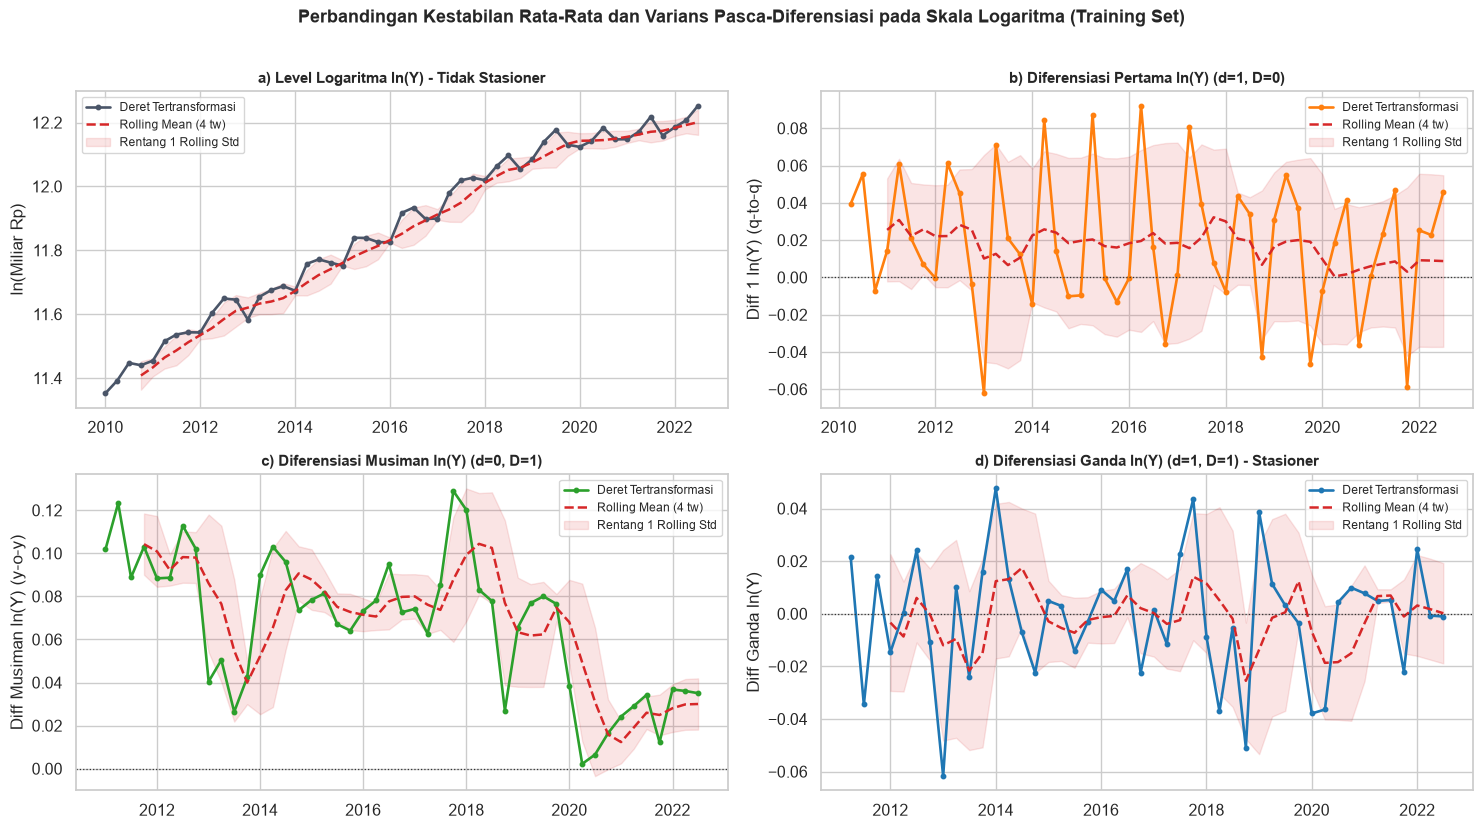

In [2]:
s_orig = pd.Series(y_train, index=train_df['tanggal'])
s_log = pd.Series(log_y_train, index=train_df['tanggal'])

diff_candidates = [
    ('Data Asli Y (Level)', 'Asli', s_orig),
    ('Diff 1 Y (d=1, D=0)', 'Asli', s_orig.diff(1).dropna()),
    ('Diff Musiman Y (d=0, D=1, s=4)', 'Asli', s_orig.diff(4).dropna()),
    ('Diff Ganda Y (d=1, D=1, s=4)', 'Asli', s_orig.diff(4).diff(1).dropna()),
    ('Logaritma ln(Y) (Level)', 'Log', s_log),
    ('Diff 1 ln(Y) (d=1, D=0)', 'Log', s_log.diff(1).dropna()),
    ('Diff Musiman ln(Y) (d=0, D=1, s=4)', 'Log', s_log.diff(4).dropna()),
    ('Diff Ganda ln(Y) (d=1, D=1, s=4)', 'Log', s_log.diff(4).diff(1).dropna()),
]

stationarity_rows = []
for label, scale, ser in diff_candidates:
    arr = ser.values
    adf_stat_c, adf_p_c, _, _, _, _ = adfuller(arr, regression='c', autolag='AIC')
    adf_stat_ct, adf_p_ct, _, _, _, _ = adfuller(arr, regression='ct', autolag='AIC')
    kpss_stat_c, kpss_p_c, _, _ = kpss(arr, regression='c', nlags='auto')
    if (adf_p_c < 0.05) and (kpss_p_c >= 0.05):
        verdict = 'STASIONER (ADF dan KPSS)'
    elif (adf_p_c >= 0.05) and (kpss_p_c >= 0.05):
        verdict = 'PARSIAL (KPSS lolos, ADF belum)'
    else:
        verdict = 'TIDAK STASIONER'
    stationarity_rows.append({
        'Deret Uji (Training Set)': label,
        'Skala': scale,
        'n': len(arr),
        'Std': round(float(np.std(arr, ddof=1)), 4),
        'ADF Stat (c)': round(float(adf_stat_c), 4),
        'ADF p (c)': round(float(adf_p_c), 4),
        'ADF p (ct)': round(float(adf_p_ct), 4),
        'KPSS Stat (c)': round(float(kpss_stat_c), 4),
        'KPSS p (c)': round(float(kpss_p_c), 4),
        'Kesimpulan (taraf 5%)': verdict,
    })

stationarity_df = pd.DataFrame(stationarity_rows)
print('=== Uji Stasioneritas Sebelum dan Sesudah Diferensiasi pada Training Set ===')
display(stationarity_df)

plot_series = [
    ('a) Level Logaritma ln(Y) - Tidak Stasioner', s_log, 'ln(Miliar Rp)', '#4a5568'),
    ('b) Diferensiasi Pertama ln(Y) (d=1, D=0)', s_log.diff(1).dropna(), 'Diff 1 ln(Y) (q-to-q)', '#ff7f0e'),
    ('c) Diferensiasi Musiman ln(Y) (d=0, D=1)', s_log.diff(4).dropna(), 'Diff Musiman ln(Y) (y-o-y)', '#2ca02c'),
    ('d) Diferensiasi Ganda ln(Y) (d=1, D=1) - Stasioner', s_log.diff(4).diff(1).dropna(), 'Diff Ganda ln(Y)', '#1f77b4'),
]

fig, axes = plt.subplots(2, 2, figsize=(15, 8.2))
for ax, (title, ser, ylabel, color) in zip(axes.flat, plot_series):
    roll_m = ser.rolling(window=4).mean()
    roll_s = ser.rolling(window=4).std()
    ax.plot(ser.index, ser.values, color=color, lw=1.9, marker='o', ms=3.2, label='Deret Tertransformasi')
    ax.plot(ser.index, roll_m.values, color='#d62728', lw=1.8, ls='--', label='Rolling Mean (4 tw)')
    ax.fill_between(ser.index, roll_m - roll_s, roll_m + roll_s, color='#d62728', alpha=0.12, label='Rentang 1 Rolling Std')
    if 'Level' not in title:
        ax.axhline(0, color='#333333', lw=0.9, ls=':')
    ax.set_title(title, fontweight='bold', fontsize=11)
    ax.set_ylabel(ylabel)
    ax.legend(loc='best', fontsize=8.5)

plt.suptitle('Perbandingan Kestabilan Rata-Rata dan Varians Pasca-Diferensiasi pada Skala Logaritma (Training Set)', fontweight='bold', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

Dari hasil uji ADF dan KPSS pada data latih, data level asli maupun logaritma memang belum stasioner. Setelah dilakukan diferensiasi ganda (d=1, D=1, s=4) pada skala logaritma, kedua uji sepakat data sudah stasioner dengan nilai ADF -6,3315 (p < 0,0001) dan KPSS 0,0387 (p = 0,1000). Untuk diferensiasi tunggal non-musiman (d=1, D=0), KPSS sudah lolos (p = 0,1000) tetapi ADF belum karena masih ada pola musiman kuartalan yang kuat. Karena nilai AIC dan BIC tidak bisa dibandingkan langsung antar orde diferensiasi yang berbeda, ketiga skenario diferensiasi pada skala logaritma tetap akan dibandingkan secara adil di data validasi.

---
## 3. Identifikasi Kandidat Orde SARIMA dari Plot ACF dan PACF

Rezim 1: Diff 1 ln(Y) (d=1, D=0) (n=50, batas 95% = +/-0.277)
  ACF signifikan  : lag 2 (-0.501), lag 4 (+0.753), lag 6 (-0.445), lag 8 (+0.684), lag 10 (-0.512), lag 12 (+0.551)
  PACF signifikan : lag 2 (-0.531), lag 3 (-0.466), lag 4 (+0.551)

Rezim 2: Diff Musiman ln(Y) (d=0, D=1, s=4) (n=47, batas 95% = +/-0.286)
  ACF signifikan  : lag 1 (+0.730), lag 2 (+0.461), lag 6 (+0.338)
  PACF signifikan : lag 1 (+0.730), lag 5 (+0.361), lag 7 (-0.336)

Rezim 3: Diff Ganda ln(Y) (d=1, D=1, s=4) (n=46, batas 95% = +/-0.289)
  ACF signifikan  : lag 4 (-0.382), lag 6 (+0.365)
  PACF signifikan : lag 4 (-0.452)



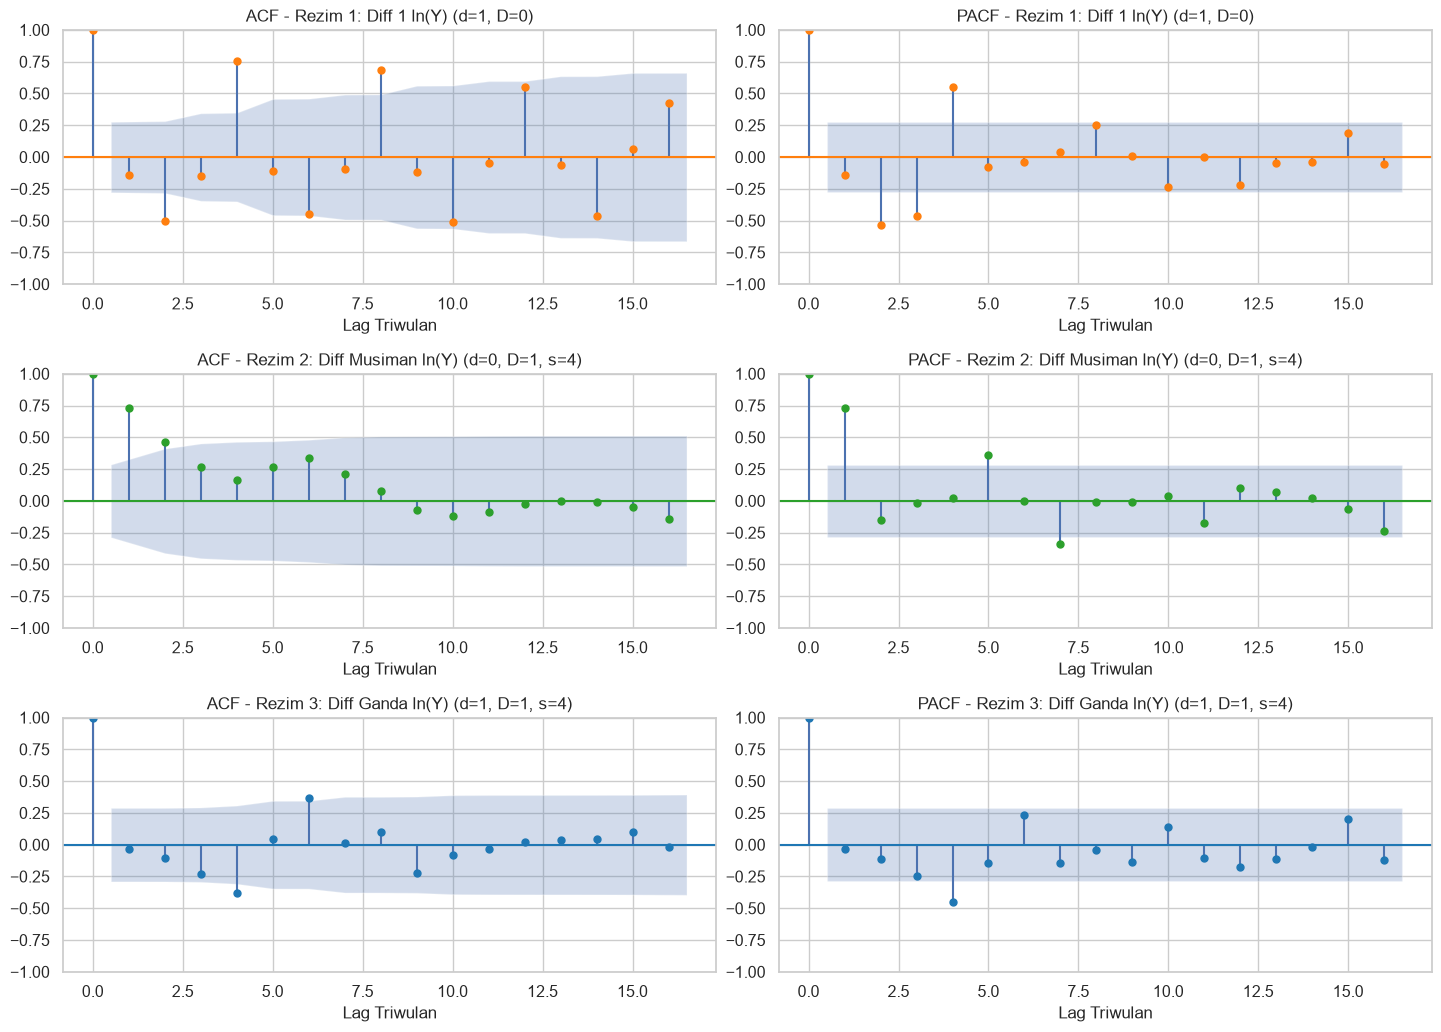

In [3]:
acf_series_list = [
    ('Rezim 1: Diff 1 ln(Y) (d=1, D=0)', s_log.diff(1).dropna(), '#ff7f0e'),
    ('Rezim 2: Diff Musiman ln(Y) (d=0, D=1, s=4)', s_log.diff(4).dropna(), '#2ca02c'),
    ('Rezim 3: Diff Ganda ln(Y) (d=1, D=1, s=4)', s_log.diff(4).diff(1).dropna(), '#1f77b4'),
]

fig, axes = plt.subplots(3, 2, figsize=(14.5, 10.5))
for row_idx, (label, ser, color) in enumerate(acf_series_list):
    plot_acf(ser.values, lags=16, ax=axes[row_idx, 0], color=color, title=f'ACF - {label}')
    plot_pacf(ser.values, lags=16, ax=axes[row_idx, 1], color=color, method='ywm', title=f'PACF - {label}')
    axes[row_idx, 0].set_xlabel('Lag Triwulan')
    axes[row_idx, 1].set_xlabel('Lag Triwulan')

    a_vals = acf(ser.values, nlags=12)
    p_vals = pacf(ser.values, nlags=12, method='ywm')
    bound = 1.96 / np.sqrt(len(ser))
    sig_acf = [f'lag {k} ({a_vals[k]:+.3f})' for k in range(1, 13) if abs(a_vals[k]) > bound]
    sig_pacf = [f'lag {k} ({p_vals[k]:+.3f})' for k in range(1, 13) if abs(p_vals[k]) > bound]
    print(f'{label} (n={len(ser)}, batas 95% = +/-{bound:.3f})')
    print(f'  ACF signifikan  : {", ".join(sig_acf) if sig_acf else "Tidak ada"}')
    print(f'  PACF signifikan : {", ".join(sig_pacf) if sig_pacf else "Tidak ada"}\n')

plt.tight_layout()
plt.show()

Pada diferensiasi pertama (d=1, D=0), plot ACF memperlihatkan lonjakan kuat di lag kelipatan 4 (lag 4, 8, dan 12) sedangkan PACF menonjol di lag 4 lalu melemah di lag 8, sehingga cocok untuk dicoba komponen AR musiman seperti SARIMA(0,1,0)(1,0,0)4, (0,1,0)(2,0,0)4, dan (0,1,0)(1,0,1)4 dengan drift. Pada diferensiasi musiman (d=0, D=1), ACF turun bertahap sejak lag 1 sementara PACF langsung terpotong setelah lag 1, yang merupakan ciri pola AR(1) sehingga kandidat utamanya adalah SARIMA(1,0,0)(1,1,0)4 dan (1,0,0)(0,1,1)4 dengan drift. Sementara pada diferensiasi ganda (d=1, D=1), lag 1 sampai 3 tidak signifikan dan hanya lag 4 yang menonjol negatif, sehingga kandidat dasarnya adalah SARIMA(0,1,0)(1,1,0)4 dan (0,1,0)(0,1,1)4.

---
## 4. Estimasi dan Seleksi Kandidat Model SARIMA (Training Set)

In [4]:
candidate_specs = [
    # Pembanding skala asli
    ('Skala Asli (Y)', 'SARIMA(0,1,0)(1,0,0)_4 + drift [Asli]', (0, 1, 0), (1, 0, 0, 4), 'c', False),
    ('Skala Asli (Y)', 'SARIMA(0,1,0)(0,1,1)_4 [Asli]',         (0, 1, 0), (0, 1, 1, 4), 'n', False),

    # Rezim 1: Logaritma, d=1, D=0, drift
    ('Rezim 1: Log (d=1, D=0)', 'SARIMA(0,1,0)(1,0,0)_4 + drift', (0, 1, 0), (1, 0, 0, 4), 'c', True),
    ('Rezim 1: Log (d=1, D=0)', 'SARIMA(0,1,0)(2,0,0)_4 + drift', (0, 1, 0), (2, 0, 0, 4), 'c', True),
    ('Rezim 1: Log (d=1, D=0)', 'SARIMA(0,1,0)(1,0,1)_4 + drift', (0, 1, 0), (1, 0, 1, 4), 'c', True),
    ('Rezim 1: Log (d=1, D=0)', 'SARIMA(0,1,1)(1,0,1)_4 + drift', (0, 1, 1), (1, 0, 1, 4), 'c', True),
    ('Rezim 1: Log (d=1, D=0)', 'SARIMA(1,1,0)(1,0,1)_4 + drift', (1, 1, 0), (1, 0, 1, 4), 'c', True),

    # Rezim 2: Logaritma, d=0, D=1, drift
    ('Rezim 2: Log (d=0, D=1)', 'SARIMA(1,0,0)(1,1,0)_4 + drift', (1, 0, 0), (1, 1, 0, 4), 'c', True),
    ('Rezim 2: Log (d=0, D=1)', 'SARIMA(1,0,0)(0,1,1)_4 + drift', (1, 0, 0), (0, 1, 1, 4), 'c', True),
    ('Rezim 2: Log (d=0, D=1)', 'SARIMA(1,0,0)(0,1,0)_4 + drift', (1, 0, 0), (0, 1, 0, 4), 'c', True),

    # Rezim 3: Logaritma, d=1, D=1, tanpa drift
    ('Rezim 3: Log (d=1, D=1)', 'SARIMA(0,1,0)(1,1,0)_4',         (0, 1, 0), (1, 1, 0, 4), 'n', True),
    ('Rezim 3: Log (d=1, D=1)', 'SARIMA(0,1,0)(0,1,1)_4',         (0, 1, 0), (0, 1, 1, 4), 'n', True),
    ('Rezim 3: Log (d=1, D=1)', 'SARIMA(0,1,1)(0,1,1)_4',         (0, 1, 1), (0, 1, 1, 4), 'n', True),
    ('Rezim 3: Log (d=1, D=1)', 'SARIMA(1,1,0)(0,1,1)_4',         (1, 1, 0), (0, 1, 1, 4), 'n', True),
]

fitted_models = {}
summary_rows = []

for regime, name, order, sorder, trend, use_log in candidate_specs:
    endog = log_y_train if use_log else y_train
    mod = SARIMAX(
        endog,
        order=order,
        seasonal_order=sorder,
        trend=trend,
        enforce_stationarity=True,
        enforce_invertibility=True,
    )
    res = mod.fit(disp=False, maxiter=500)
    burn = order[1] + sorder[1] * sorder[3]
    resid_eff = np.asarray(res.resid)[burn:]
    n_eff = len(resid_eff)
    k = len(res.params)
    aicc = float(res.aic + (2 * k * (k + 1)) / max(n_eff - k - 1, 1))

    n_arma = order[0] + order[2] + sorder[0] + sorder[2]
    lb = acorr_ljungbox(resid_eff, lags=[4, 8, 12], model_df=n_arma, return_df=True)
    lb4_p, lb8_p, lb12_p = [float(x) for x in lb['lb_pvalue'].values]
    sw_p = float(stats.shapiro(resid_eff)[1])
    jb_p = float(stats.jarque_bera(resid_eff)[1])
    arch_p = float(het_arch(resid_eff, nlags=4)[1])

    diag_pass = (lb4_p >= 0.05) and (lb8_p >= 0.05) and (lb12_p >= 0.05) and (sw_p >= 0.05) and (arch_p >= 0.05)

    fitted_models[name] = {
        'res': res,
        'regime': regime,
        'order': order,
        'sorder': sorder,
        'trend': trend,
        'use_log': use_log,
        'burn': burn,
        'resid_eff': resid_eff,
        'aicc': aicc,
        'diag_pass': diag_pass,
    }

    summary_rows.append({
        'Rezim': regime,
        'Kandidat Model SARIMA': name,
        'k': k,
        'AIC': round(float(res.aic), 2),
        'AICc': round(aicc, 2),
        'BIC': round(float(res.bic), 2),
        'LB(4) p': round(lb4_p, 4),
        'LB(8) p': round(lb8_p, 4),
        'LB(12) p': round(lb12_p, 4),
        'SW p': round(sw_p, 4),
        'JB p': round(jb_p, 4),
        'ARCH(4) p': round(arch_p, 4),
        'Lolos Diagnostik': 'YA' if diag_pass else 'TIDAK',
    })

candidates_df = pd.DataFrame(summary_rows)
print('=== Ringkasan Estimasi dan Uji Diagnostik Kandidat SARIMA (Training Set, N = 51) ===')
display(candidates_df)

=== Ringkasan Estimasi dan Uji Diagnostik Kandidat SARIMA (Training Set, N = 51) ===


,Rezim,Kandidat Model SARIMA,k,AIC,AICc,BIC,LB(4) p,LB(8) p,LB(12) p,SW p,JB p,ARCH(4) p,Lolos Diagnostik
0,Skala Asli (Y),"SARIMA(0,1,0)(1,0,0)_4 + drift [Asli]",3,1005.10,1005.62,1010.83,0.0000,0.0000,0.0000,0.3048,0.4921,0.0328,TIDAK
1,Skala Asli (Y),"SARIMA(0,1,0)(0,1,1)_4 [Asli]",2,881.14,881.42,884.80,0.0104,0.0050,0.0057,0.1865,0.4125,0.1985,TIDAK
2,"Rezim 1: Log (d=1, D=0)","SARIMA(0,1,0)(1,0,0)_4 + drift",3,-231.50,-230.98,-225.76,0.1320,0.1079,0.1037,0.2128,0.2185,0.6727,YA
3,"Rezim 1: Log (d=1, D=0)","SARIMA(0,1,0)(2,0,0)_4 + drift",4,-234.96,-234.07,-227.31,0.1752,0.1800,0.2795,0.1716,0.1768,0.8778,YA
4,"Rezim 1: Log (d=1, D=0)","SARIMA(0,1,0)(1,0,1)_4 + drift",4,-234.12,-233.23,-226.47,0.1759,0.1063,0.1686,0.2389,0.1950,0.9167,YA
5,"Rezim 1: Log (d=1, D=0)","SARIMA(0,1,1)(1,0,1)_4 + drift",5,-233.47,-232.11,-223.91,0.0709,0.1401,0.1601,0.3528,0.1083,0.7209,YA
6,"Rezim 1: Log (d=1, D=0)","SARIMA(1,1,0)(1,0,1)_4 + drift",5,-233.15,-231.78,-223.59,0.0643,0.1282,0.1636,0.3081,0.1160,0.7616,YA
7,"Rezim 2: Log (d=0, D=1)","SARIMA(1,0,0)(1,1,0)_4 + drift",4,-224.52,-223.57,-217.12,0.4872,0.0878,0.1883,0.9437,0.6852,0.7884,YA
8,"Rezim 2: Log (d=0, D=1)","SARIMA(1,0,0)(0,1,1)_4 + drift",4,-224.08,-223.13,-216.68,0.4825,0.0985,0.2141,0.8663,0.6116,0.7522,YA
9,"Rezim 2: Log (d=0, D=1)","SARIMA(1,0,0)(0,1,0)_4 + drift",3,-221.36,-220.80,-215.81,0.1118,0.0359,0.0932,0.5335,0.7971,0.2783,TIDAK


Dua model pembanding pada skala asli gagal pada uji Ljung-Box (p paling tinggi 0,0104), yang menunjukkan bahwa transformasi logaritma memang diperlukan agar residual bebas autokorelasi. Pada skala logaritma, kandidat di rezim d=1, D=0 dengan drift dan rezim d=0, D=1 dengan drift lolos seluruh uji diagnostik residual. Di rezim d=1, D=0, nilai AICc terbaik dicapai oleh SARIMA(0,1,0)(2,0,0)4 + drift (-234,07) disusul (0,1,0)(1,0,1)4 + drift (-233,23) dan model paling sederhana (0,1,0)(1,0,0)4 + drift (-230,98). Di rezim d=0, D=1, yang terbaik adalah SARIMA(1,0,0)(1,1,0)4 + drift (-223,57). Sebaliknya, semua kandidat diferensiasi ganda (d=1, D=1) belum lolos uji Ljung-Box pada lag 8 dan 12 (p di bawah 0,05) karena masih menyisakan korelasi di lag 6.

---
## 5. Uji Diagnostik Residual Model Finalis

=== Estimasi Parameter dan Stabilitas Akar AR Model Finalis SARIMA ===


,Model,Parameter,Estimasi,Std. Error,z-Stat,p-value,Min |Akar AR|
0,"SARIMA(0,1,0)(1,0,0)_4 + drift",intercept,0.003521,0.003176,1.109,0.2675,1.057
1,"SARIMA(0,1,0)(1,0,0)_4 + drift",ar.S.L4,0.800539,0.086116,9.296,0.0000,1.057
2,"SARIMA(0,1,0)(1,0,0)_4 + drift",sigma2,0.000467,0.000094,4.978,0.0000,1.057
3,"SARIMA(0,1,0)(2,0,0)_4 + drift",intercept,0.002385,0.002783,0.857,0.3913,1.027
4,"SARIMA(0,1,0)(2,0,0)_4 + drift",ar.S.L4,0.525338,0.133865,3.924,0.0001,1.027
5,"SARIMA(0,1,0)(2,0,0)_4 + drift",ar.S.L8,0.335730,0.138574,2.423,0.0154,1.027
6,"SARIMA(0,1,0)(2,0,0)_4 + drift",sigma2,0.000412,0.000075,5.473,0.0000,1.027
7,"SARIMA(1,0,0)(1,1,0)_4 + drift",intercept,0.015027,0.010056,1.494,0.1351,1.198
8,"SARIMA(1,0,0)(1,1,0)_4 + drift",ar.L1,0.835043,0.093724,8.910,0.0000,1.198
9,"SARIMA(1,0,0)(1,1,0)_4 + drift",ar.S.L4,-0.353523,0.132854,-2.661,0.0078,1.198


Rata-rata pertumbuhan implisit SARIMA(0,1,0)(1,0,0)_4 + drift: 1.78% per triwulan atau 7.32% per tahun


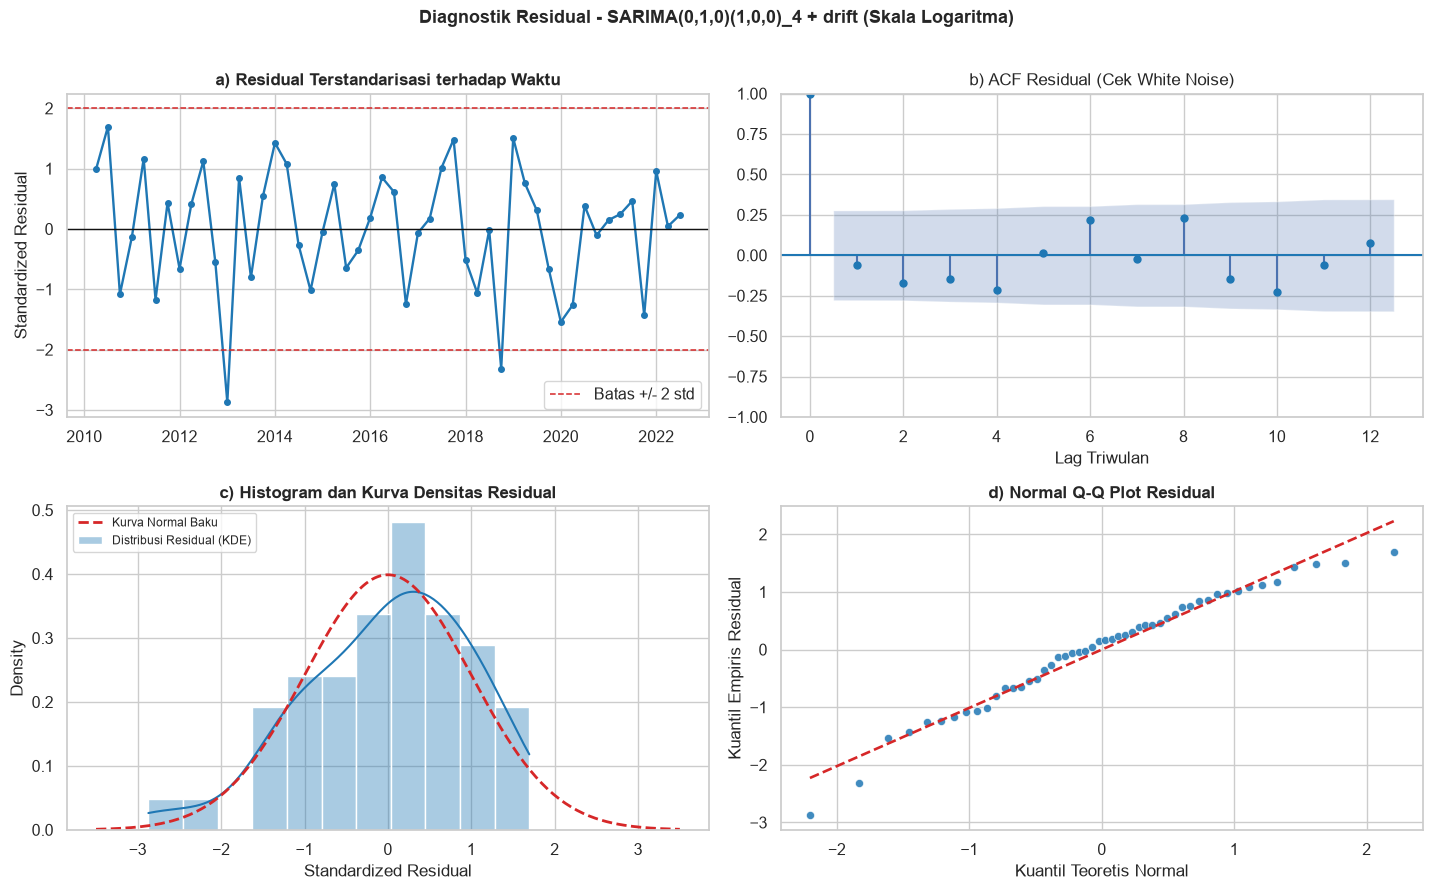

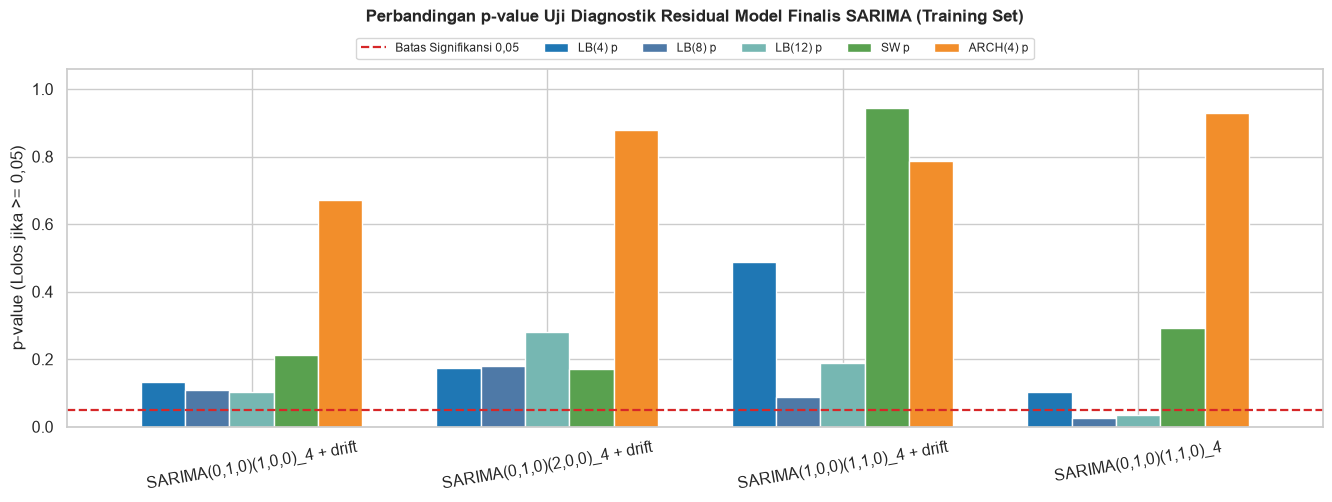

In [5]:
top_finalists = [
    'SARIMA(0,1,0)(1,0,0)_4 + drift',
    'SARIMA(0,1,0)(2,0,0)_4 + drift',
    'SARIMA(1,0,0)(1,1,0)_4 + drift',
]

param_rows = []
for name in top_finalists:
    res = fitted_models[name]['res']
    min_ar_root = float(np.min(np.abs(res.arroots))) if len(res.arroots) > 0 else np.nan
    for pname, coef, se, zval, pval in zip(res.param_names, res.params, res.bse, res.zvalues, res.pvalues):
        param_rows.append({
            'Model': name,
            'Parameter': pname,
            'Estimasi': round(float(coef), 6),
            'Std. Error': round(float(se), 6),
            'z-Stat': round(float(zval), 3),
            'p-value': round(float(pval), 4),
            'Min |Akar AR|': round(min_ar_root, 3) if not np.isnan(min_ar_root) else '-',
        })

param_df = pd.DataFrame(param_rows)
print('=== Estimasi Parameter dan Stabilitas Akar AR Model Finalis SARIMA ===')
display(param_df)

res_best_pars = fitted_models['SARIMA(0,1,0)(1,0,0)_4 + drift']['res']
params_arr = np.asarray(res_best_pars.params)
c_hat = float(params_arr[0])
phi4_hat = float(params_arr[1])
implied_qoq = c_hat / (1.0 - phi4_hat)
print(
    f"Rata-rata pertumbuhan implisit SARIMA(0,1,0)(1,0,0)_4 + drift: "
    f"{(np.exp(implied_qoq) - 1) * 100:.2f}% per triwulan atau {(np.exp(4 * implied_qoq) - 1) * 100:.2f}% per tahun"
)

# Panel diagnostik 2x2 untuk SARIMA(0,1,0)(1,0,0)_4 + drift
info = fitted_models['SARIMA(0,1,0)(1,0,0)_4 + drift']
resid_eff = info['resid_eff']
std_resid = (resid_eff - np.mean(resid_eff)) / np.std(resid_eff, ddof=1)
dates_eff = train_df['tanggal'].iloc[info['burn']:]

fig, axes = plt.subplots(2, 2, figsize=(14.5, 8.8))

axes[0, 0].plot(dates_eff, std_resid, color=PALETTE['sarima_best'], lw=1.7, marker='o', ms=4)
axes[0, 0].axhline(0, color='#111111', lw=1.0)
axes[0, 0].axhline(2, color='#d62728', ls='--', lw=1.1, label='Batas +/- 2 std')
axes[0, 0].axhline(-2, color='#d62728', ls='--', lw=1.1)
axes[0, 0].set_title('a) Residual Terstandarisasi terhadap Waktu', fontweight='bold')
axes[0, 0].set_ylabel('Standardized Residual')
axes[0, 0].legend(loc='lower right')

plot_acf(resid_eff, lags=12, ax=axes[0, 1], color=PALETTE['sarima_best'],
         title='b) ACF Residual (Cek White Noise)')
axes[0, 1].set_xlabel('Lag Triwulan')

sns.histplot(std_resid, bins=11, stat='density', kde=True, color=PALETTE['sarima_best'],
             alpha=0.38, ax=axes[1, 0], label='Distribusi Residual (KDE)')
x_grid = np.linspace(-3.5, 3.5, 200)
axes[1, 0].plot(x_grid, stats.norm.pdf(x_grid), color='#d62728', ls='--', lw=2.0, label='Kurva Normal Baku')
axes[1, 0].set_title('c) Histogram dan Kurva Densitas Residual', fontweight='bold')
axes[1, 0].set_xlabel('Standardized Residual')
axes[1, 0].legend(loc='upper left', fontsize=8.8)

(osm, osr), (slope, intercept, _) = stats.probplot(std_resid, dist='norm')
axes[1, 1].scatter(osm, osr, color=PALETTE['sarima_best'], s=34, alpha=0.85, edgecolor='white', lw=0.5)
axes[1, 1].plot(osm, slope * osm + intercept, color='#d62728', lw=1.9, ls='--')
axes[1, 1].set_title('d) Normal Q-Q Plot Residual', fontweight='bold')
axes[1, 1].set_xlabel('Kuantil Teoretis Normal')
axes[1, 1].set_ylabel('Kuantil Empiris Residual')

plt.suptitle('Diagnostik Residual - SARIMA(0,1,0)(1,0,0)_4 + drift (Skala Logaritma)', fontweight='bold', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

# Perbandingan p-value diagnostik lintas finalis
diag_plot_models = [
    'SARIMA(0,1,0)(1,0,0)_4 + drift',
    'SARIMA(0,1,0)(2,0,0)_4 + drift',
    'SARIMA(1,0,0)(1,1,0)_4 + drift',
    'SARIMA(0,1,0)(1,1,0)_4',
]
diag_sub = candidates_df[candidates_df['Kandidat Model SARIMA'].isin(diag_plot_models)].set_index('Kandidat Model SARIMA')
diag_sub = diag_sub.loc[diag_plot_models, ['LB(4) p', 'LB(8) p', 'LB(12) p', 'SW p', 'ARCH(4) p']]

fig, ax = plt.subplots(figsize=(13.5, 5.2))
diag_sub.plot(kind='bar', ax=ax, width=0.75,
              color=['#1f77b4', '#4e79a7', '#76b7b2', '#59a14f', '#f28e2b'])
ax.axhline(0.05, color='#d62728', ls='--', lw=1.6, label='Batas Signifikansi 0,05')
ax.set_title('Perbandingan p-value Uji Diagnostik Residual Model Finalis SARIMA (Training Set)', fontweight='bold', pad=34)
ax.set_ylabel('p-value (Lolos jika >= 0,05)')
ax.set_xlabel('')
ax.set_ylim(0, 1.06)
ax.tick_params(axis='x', rotation=10)
ax.legend(bbox_to_anchor=(0.5, 1.01), loc='lower center', ncol=6, fontsize=8.8, frameon=True)
plt.tight_layout()
plt.show()

Ketiga model finalis dari rezim diferensiasi tunggal memiliki akar AR di atas 1 sehingga memenuhi syarat stasioneritas. Pada SARIMA(0,1,0)(1,0,0)4 + drift, koefisien AR musiman lag 4 sebesar 0,8005 sangat signifikan (p < 0,0001), sedangkan konstanta drift tetap dipertahankan karena mencerminkan rata-rata pertumbuhan PDB riil sekitar 1,78 persen per triwulan (7,32 persen per tahun). Dari empat panel diagnostik dan grafik perbandingan p-value, residual ketiga model finalis tersebut menyebar acak di sekitar nol, tidak menunjukkan pola autokorelasi, mendekati distribusi normal, dan memiliki varians yang stabil (semua p-value di atas 0,05).

---
## 6. Evaluasi Peramalan pada Validation Set (2022-Q4 sampai 2024-Q3)

=== Perbandingan Performa Model SARIMA vs Baseline pada Validation Set (2022-Q4 s.d. 2024-Q3) ===


,Model,Diagnostik,RMSE (Miliar Rp),MAE (Miliar Rp),MAPE (%),sMAPE (%),MASE,95% PI Cov.,1-Step RMSE
0,"SARIMA(0,1,0)(1,0,0)_4 + drift",Lolos,3189.90,2177.65,1.023,1.033,0.235,8/8,3457.02
1,"SARIMA(0,1,0)(2,0,0)_4 + drift",Lolos,4004.44,3251.33,1.511,1.528,0.350,8/8,3508.71
2,"SARIMA(1,1,0)(1,0,1)_4 + drift",Lolos,4183.43,3454.39,1.605,1.623,0.372,8/8,3370.87
3,"SARIMA(0,1,0)(1,0,1)_4 + drift",Lolos,4261.87,3521.89,1.636,1.656,0.380,8/8,3513.16
4,"SARIMA(0,1,1)(1,0,1)_4 + drift",Lolos,4345.35,3618.83,1.680,1.701,0.390,8/8,3352.89
5,"SARIMA(1,0,0)(1,1,0)_4 + drift",Lolos,4475.78,3763.61,1.735,1.735,0.406,8/8,3900.88
6,"SARIMA(1,0,0)(0,1,1)_4 + drift",Lolos,4807.52,4021.46,1.849,1.843,0.433,8/8,3866.54
7,"SARIMA(0,1,0)(0,1,1)_4",Tidak Lolos,6448.36,5542.14,2.568,2.613,0.597,8/8,4180.09
8,"SARIMA(0,1,0)(1,1,0)_4",Tidak Lolos,6594.23,5658.86,2.621,2.669,0.610,8/8,4284.61
9,Baseline 1 - Naive (Last Value),Baseline,9407.24,7475.00,3.387,3.474,0.806,-,-



=== Detail Peramalan per Triwulan pada Validation Set (SARIMA Terpilih vs Aktual) ===


,Periode,Aktual (M Rp),Naive (M Rp),SARIMA Terpilih (M Rp),Galat SARIMA (M Rp),Galat Abs. (%),PI 95% Bawah,PI 95% Atas
0,2022-Q4,207444.4,209604.2,200708.6,-6735.8,3.25,192388.6,209388.4
1,2023-Q1,206187.0,209604.2,205532.0,-655.0,0.32,193587.3,218213.7
2,2023-Q2,209512.8,209604.2,210048.6,535.8,0.26,195197.0,226030.1
3,2023-Q3,216474.8,209604.2,218627.6,2152.8,0.99,200877.7,237945.9
4,2023-Q4,217221.1,209604.2,211912.7,-5308.4,2.44,189093.7,237485.4
5,2024-Q1,218284.7,209604.2,216741.7,-1543.0,0.71,188976.9,248585.7
6,2024-Q2,221106.5,209604.2,221324.4,217.9,0.10,189195.1,258909.9
7,2024-Q3,229065.5,209604.2,229338.0,272.5,0.12,192636.3,273032.3


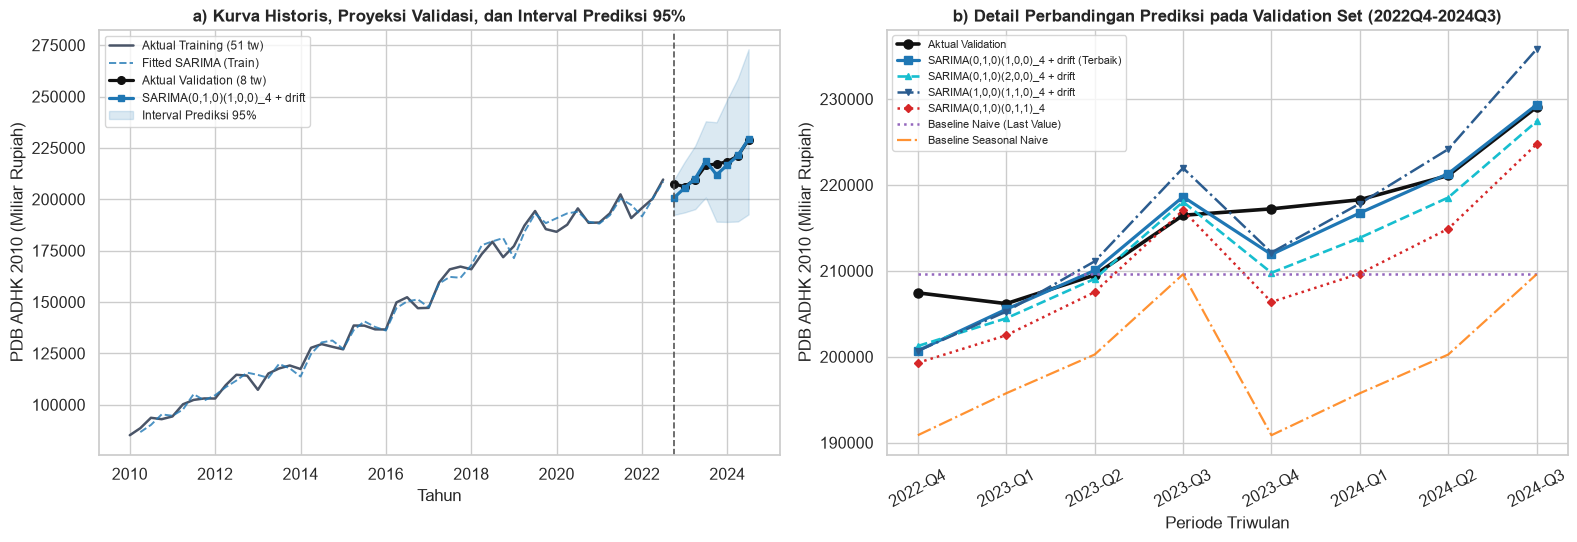

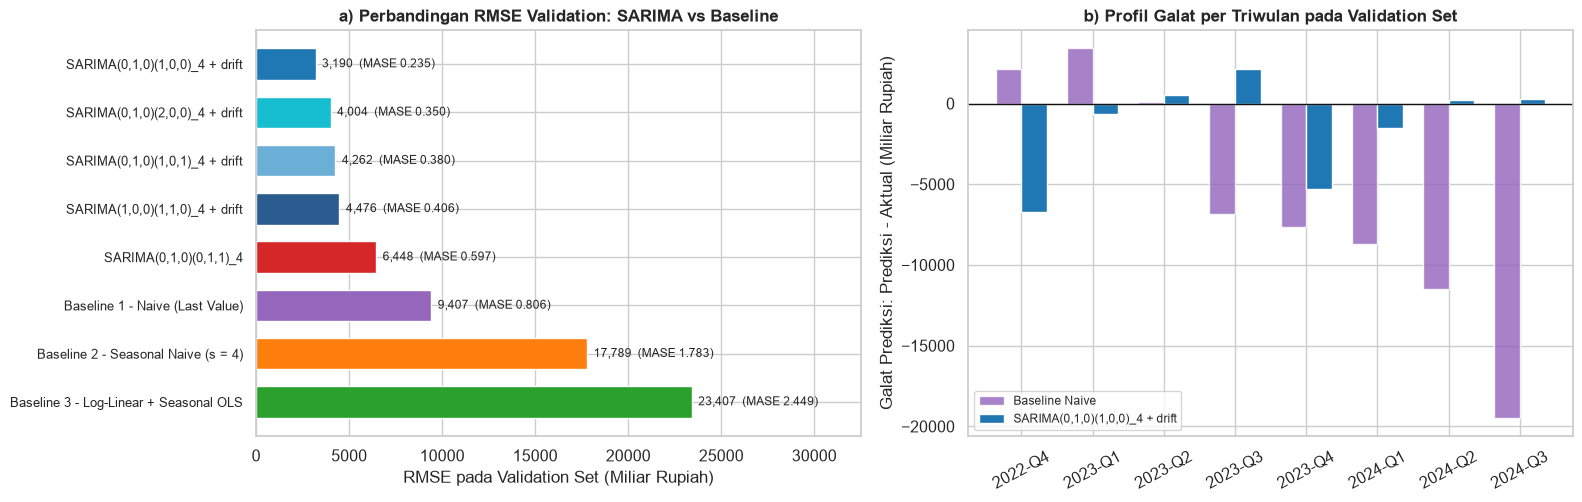

In [6]:
eval_models = [
    'SARIMA(0,1,0)(1,0,0)_4 + drift',
    'SARIMA(0,1,0)(2,0,0)_4 + drift',
    'SARIMA(0,1,0)(1,0,1)_4 + drift',
    'SARIMA(0,1,1)(1,0,1)_4 + drift',
    'SARIMA(1,1,0)(1,0,1)_4 + drift',
    'SARIMA(1,0,0)(1,1,0)_4 + drift',
    'SARIMA(1,0,0)(0,1,1)_4 + drift',
    'SARIMA(0,1,0)(1,1,0)_4',
    'SARIMA(0,1,0)(0,1,1)_4',
]

val_rows = [
    {'Model': 'Baseline 1 - Naive (Last Value)', 'Diagnostik': 'Baseline', **evaluate_forecast(y_val, pred_val_naive), '95% PI Cov.': '-', '1-Step RMSE': '-'},
    {'Model': 'Baseline 2 - Seasonal Naive (s = 4)', 'Diagnostik': 'Baseline', **evaluate_forecast(y_val, pred_val_snaive), '95% PI Cov.': '-', '1-Step RMSE': '-'},
    {'Model': 'Baseline 3 - Log-Linear + Seasonal OLS', 'Diagnostik': 'Baseline', **evaluate_forecast(y_val, pred_val_ols), '95% PI Cov.': '-', '1-Step RMSE': '-'},
]

val_forecasts = {}
val_cis = {}
y_tr_val_log = np.log(np.concatenate([y_train, y_val]))

for name in eval_models:
    info = fitted_models[name]
    res = info['res']
    fc = res.get_forecast(steps=horizon_val)
    pred = np.exp(fc.predicted_mean)
    ci = np.exp(fc.conf_int(alpha=0.05))

    val_forecasts[name] = np.asarray(pred)
    val_cis[name] = np.asarray(ci)

    in_ci = int(np.sum((y_val >= val_cis[name][:, 0]) & (y_val <= val_cis[name][:, 1])))

    # Cek stabilitas 1-langkah (parameter latih tetap, tanpa refit)
    res_1step = res.apply(y_tr_val_log)
    pred_1step = np.exp(np.asarray(res_1step.fittedvalues)[-horizon_val:])
    rmse_1step = float(np.sqrt(mean_squared_error(y_val, pred_1step)))

    val_rows.append({
        'Model': name,
        'Diagnostik': 'Lolos' if info['diag_pass'] else 'Tidak Lolos',
        **evaluate_forecast(y_val, val_forecasts[name]),
        '95% PI Cov.': f'{in_ci}/8',
        '1-Step RMSE': round(rmse_1step, 2),
    })

val_comparison_df = pd.DataFrame(val_rows).sort_values('RMSE (Miliar Rp)').reset_index(drop=True)
print('=== Perbandingan Performa Model SARIMA vs Baseline pada Validation Set (2022-Q4 s.d. 2024-Q3) ===')
display(val_comparison_df)

best_name = 'SARIMA(0,1,0)(1,0,0)_4 + drift'
best_pred = val_forecasts[best_name]
best_ci = val_cis[best_name]

quarter_detail = pd.DataFrame({
    'Periode': val_df['periode'].values,
    'Aktual (M Rp)': np.round(y_val, 1),
    'Naive (M Rp)': np.round(pred_val_naive, 1),
    'SARIMA Terpilih (M Rp)': np.round(best_pred, 1),
    'Galat SARIMA (M Rp)': np.round(best_pred - y_val, 1),
    'Galat Abs. (%)': np.round(np.abs(best_pred - y_val) / y_val * 100, 2),
    'PI 95% Bawah': np.round(best_ci[:, 0], 1),
    'PI 95% Atas': np.round(best_ci[:, 1], 1),
})
print('\n=== Detail Peramalan per Triwulan pada Validation Set (SARIMA Terpilih vs Aktual) ===')
display(quarter_detail)

# Grafik 1: Kurva historis dan zoom perbandingan validasi
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6))

res_best = fitted_models[best_name]['res']
fitted_train_best = np.exp(np.asarray(res_best.fittedvalues)[1:])
axes[0].plot(train_df['tanggal'], y_train, color=PALETTE['train'], lw=1.8, label='Aktual Training (51 tw)')
axes[0].plot(train_df['tanggal'].iloc[1:], fitted_train_best, color=PALETTE['sarima_best'], ls='--', lw=1.4, alpha=0.8, label='Fitted SARIMA (Train)')
axes[0].plot(val_df['tanggal'], y_val, color=PALETTE['actual'], marker='o', ms=5.5, lw=2.3, label='Aktual Validation (8 tw)')
axes[0].plot(val_df['tanggal'], best_pred, color=PALETTE['sarima_best'], marker='s', ms=5, lw=2.3, label='SARIMA(0,1,0)(1,0,0)_4 + drift')
axes[0].fill_between(val_df['tanggal'], best_ci[:, 0], best_ci[:, 1], color=PALETTE['sarima_best'], alpha=0.16, label='Interval Prediksi 95%')
axes[0].axvline(val_df['tanggal'].iloc[0], color='#555555', ls='--', lw=1.2)
axes[0].set_title('a) Kurva Historis, Proyeksi Validasi, dan Interval Prediksi 95%', fontweight='bold')
axes[0].set_xlabel('Tahun')
axes[0].set_ylabel('PDB ADHK 2010 (Miliar Rupiah)')
axes[0].legend(loc='upper left', fontsize=8.4)

x_periods = val_df['periode'].values
axes[1].plot(x_periods, y_val, color=PALETTE['actual'], marker='o', ms=6.5, lw=2.6, label='Aktual Validation')
axes[1].plot(x_periods, best_pred, color=PALETTE['sarima_best'], marker='s', ms=5.5, lw=2.3, label='SARIMA(0,1,0)(1,0,0)_4 + drift (Terbaik)')
axes[1].plot(x_periods, val_forecasts['SARIMA(0,1,0)(2,0,0)_4 + drift'], color=PALETTE['sarima_alt1'], ls='--', marker='^', ms=5, lw=1.9, label='SARIMA(0,1,0)(2,0,0)_4 + drift')
axes[1].plot(x_periods, val_forecasts['SARIMA(1,0,0)(1,1,0)_4 + drift'], color=PALETTE['sarima_alt2'], ls='-.', marker='v', ms=5, lw=1.8, label='SARIMA(1,0,0)(1,1,0)_4 + drift')
axes[1].plot(x_periods, val_forecasts['SARIMA(0,1,0)(0,1,1)_4'], color=PALETTE['sarima_alt3'], ls=':', marker='D', ms=4.5, lw=1.8, label='SARIMA(0,1,0)(0,1,1)_4')
axes[1].plot(x_periods, pred_val_naive, color=PALETTE['naive'], ls=':', lw=1.8, label='Baseline Naive (Last Value)')
axes[1].plot(x_periods, pred_val_snaive, color=PALETTE['snaive'], ls='-.', lw=1.6, alpha=0.85, label='Baseline Seasonal Naive')
axes[1].set_title('b) Detail Perbandingan Prediksi pada Validation Set (2022Q4-2024Q3)', fontweight='bold')
axes[1].set_xlabel('Periode Triwulan')
axes[1].set_ylabel('PDB ADHK 2010 (Miliar Rupiah)')
axes[1].tick_params(axis='x', rotation=28)
axes[1].legend(loc='upper left', fontsize=8.0)

plt.tight_layout()
plt.show()

# Grafik 2: Perbandingan RMSE dan galat per triwulan
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))

bar_models = [
    'SARIMA(0,1,0)(1,0,0)_4 + drift',
    'SARIMA(0,1,0)(2,0,0)_4 + drift',
    'SARIMA(0,1,0)(1,0,1)_4 + drift',
    'SARIMA(1,0,0)(1,1,0)_4 + drift',
    'SARIMA(0,1,0)(0,1,1)_4',
    'Baseline 1 - Naive (Last Value)',
    'Baseline 2 - Seasonal Naive (s = 4)',
    'Baseline 3 - Log-Linear + Seasonal OLS',
]
bar_df = val_comparison_df[val_comparison_df['Model'].isin(bar_models)].set_index('Model').loc[bar_models]
bar_colors = [
    PALETTE['sarima_best'], PALETTE['sarima_alt1'], '#6baed6',
    PALETTE['sarima_alt2'], PALETTE['sarima_alt3'], PALETTE['naive'], PALETTE['snaive'], PALETTE['ols'],
]
y_pos = np.arange(len(bar_df))
bars = axes[0].barh(y_pos, bar_df['RMSE (Miliar Rp)'].values, color=bar_colors, height=0.65)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(bar_df.index, fontsize=9)
axes[0].invert_yaxis()
axes[0].set_xlabel('RMSE pada Validation Set (Miliar Rupiah)')
axes[0].set_title('a) Perbandingan RMSE Validation: SARIMA vs Baseline', fontweight='bold')
axes[0].set_xlim(0, 32500)
for bar, rmse_v, mase_v in zip(bars, bar_df['RMSE (Miliar Rp)'].values, bar_df['MASE'].values):
    axes[0].text(rmse_v + 350, bar.get_y() + bar.get_height() / 2,
                 f'{rmse_v:,.0f}  (MASE {mase_v:.3f})', va='center', fontsize=8.4)

err_sarima = best_pred - y_val
err_naive = pred_val_naive - y_val
x_idx = np.arange(len(x_periods))
w = 0.36
axes[1].bar(x_idx - w / 2, err_naive, width=w, color=PALETTE['naive'], alpha=0.82, label='Baseline Naive')
axes[1].bar(x_idx + w / 2, err_sarima, width=w, color=PALETTE['sarima_best'], label='SARIMA(0,1,0)(1,0,0)_4 + drift')
axes[1].axhline(0, color='#111111', lw=1.0)
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(x_periods, rotation=28)
axes[1].set_ylabel('Galat Prediksi: Prediksi - Aktual (Miliar Rupiah)')
axes[1].set_title('b) Profil Galat per Triwulan pada Validation Set', fontweight='bold')
axes[1].legend(loc='lower left', fontsize=8.8)

plt.tight_layout()
plt.show()

Semua kandidat SARIMA pada skala logaritma jauh lebih akurat dibandingkan ketiga baseline dari Progress 1. Model terbaik di data validasi adalah SARIMA(0,1,0)(1,0,0)4 + drift dengan RMSE 3.189,90 miliar rupiah, MAE 2.177,65 miliar rupiah, MAPE 1,023 persen, sMAPE 1,033 persen, dan MASE 0,235. Hasil ini menurunkan RMSE sebesar 66,1 persen dibanding Naive (9.407,24 miliar rupiah) dan 82,1 persen dibanding Seasonal Naive (17.789,37 miliar rupiah), serta seluruh 8 triwulan aktual masuk ke dalam interval prediksi 95 persen.

Jika dilihat per triwulan, prediksi SARIMA sangat rapat pada Q1 sampai Q3 dengan galat di bawah 1 persen, sementara kesalahan terbesar muncul di Q4 (2022-Q4 meleset -6.735,8 miliar rupiah dan 2023-Q4 meleset -5.308,4 miliar rupiah) karena penurunan Q4 pasca-2022 tidak sedalam pola historis tahun-tahun sebelumnya. Model diferensiasi ganda seperti SARIMA(0,1,0)(0,1,1)4 justru cenderung memprediksi terlalu rendah (RMSE 6.448,36 miliar rupiah) karena terlalu terbawa pelandaian pertumbuhan masa pandemi.

---
## 7. Ringkasan Progress 3

Pada Progress 3 ini, pemodelan statistik utama menggunakan SARIMA telah selesai diuji pada data latih dan dievaluasi pada data validasi tanpa menyentuh data uji. Transformasi logaritma terbukti dibutuhkan karena model pada skala asli gagal memenuhi asumsi white noise. Di antara seluruh kandidat, SARIMA(0,1,0)(1,0,0)4 + drift pada skala logaritma dipilih sebagai model terbaik karena paling sederhana (3 parameter), lolos seluruh uji diagnostik residual (Ljung-Box lag 4, 8, 12 di atas 0,10; Shapiro-Wilk 0,2128; Jarque-Bera 0,2185; ARCH-LM 0,6727), dan mencatat galat validasi terkecil dengan RMSE 3.189,90 miliar rupiah, MAE 2.177,65 miliar rupiah, MAPE 1,023 persen, serta MASE 0,235.

Langkah selanjutnya pada Progress 4 adalah membangun model pembanding Support Vector Regression (SVR-RBF) menggunakan fitur lag musiman dan kalender pada pembagian data validasi yang sama. Setelah kedua model selesai dituning di data validasi, evaluasi akhir pada data uji (2024-Q4 sampai 2026-Q3) akan dilakukan secara adil pada Progress 5 sebelum penyusunan poster akhir.